# TP 2 — Linear Regression, Gradient Descent and Regularization

### Instructions

- Work through the notebook **from top to bottom**; later cells depend on code you write earlier.
- Replace each `# TODO` with your own Python code. Use the markdown answer spaces to explain your results.
- Include plots with titles, axis labels and legends where requested.
- Use **NumPy from scratch in Part I**. Scikit-learn is introduced for polynomial regression in Part II and used in Part III.
- Use a fixed random seed when reproducibility is requested or helpful.
- Complete all requested **training and test MSE comparisons**. Explain in Part III why **hyperparameter selection** should use validation or cross-validation rather than repeatedly choosing based on the test set.

**Required packages:** `numpy`, `pandas`, `matplotlib`, `scikit-learn`.


---
# Part I — Simple Linear Regression from Scratch

**Objective:** Generate synthetic linear data; implement MSE, least squares and Gradient Descent using NumPy; compare the estimated models on held-out observations.

## A. Data Generation and Train/Test Split

Generate a synthetic dataset following

$$y=ax+b+\varepsilon$$

where $X$ is the input variable, $a$ is the slope, $b$ is the intercept, and $\varepsilon$ is random noise.

#### Question 1

Import `numpy` as `np` and `matplotlib.pyplot` as `plt`.

In [143]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown # I used this import to more organized displays.

#### Question 2

Generate **100** input values `X` randomly distributed between **0 and 10** using `np.random.rand()`.

In [144]:
X = np.random.rand(100) * 10

#### Question 3

Define the true parameters $a_{\mathrm{true}}=3$ and $b_{\mathrm{true}}=5$. Generate target values using

$$y=3X+5+\varepsilon,\qquad\varepsilon\sim\mathcal{N}(0,2^2).$$

Gaussian noise must have mean **0** and standard deviation **2**.

In [145]:
a = 3 ; b = 5 
eps = np.random.normal(0, 2, size=len(X))
y = a * X + b + eps

#### Question 4

Display the shapes of `X` and `y`. Explain the difference between an **input feature** and a **target variable**.

In [146]:
print(X.shape , "\n" , y.shape)

(100,) 
 (100,)


**Your interpretation / answer:**

*Write your response here.* Both $X$ and $y$ has shape of $100$

#### Question 5

Split the data into **80% training** and **20% testing** subsets **from scratch**, without `train_test_split()`. Shuffle before splitting, keeping matching `X`–`y` observations paired.

In [147]:
indices = np.random.permutation(len(X))
split = int(0.8 * len(X))

X_train, X_test = X[indices[:split]], X[indices[split:]]
Y_train, Y_test = y[indices[:split]], y[indices[split:]]

#### Question 6

Display the numbers of training and testing observations.

In [148]:
print("Training Observation :" , len(X_train))
print("Test Observation :" , len(X_test))

Training Observation : 80
Test Observation : 20


## B. Data Visualization and Initial Model

#### Question 7

Create a **scatter plot** of the training data. Include a title and axis labels (`X`, `y`).

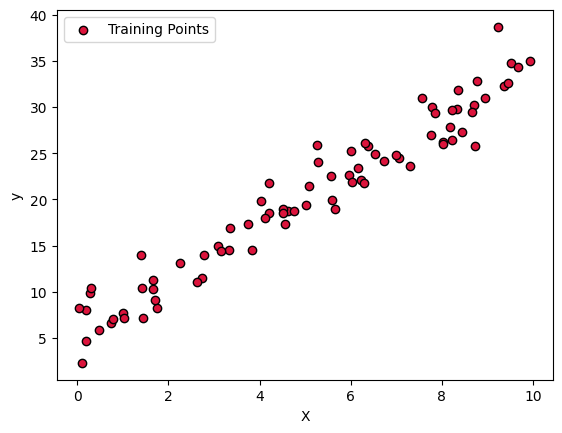

In [149]:
fig , ax = plt.subplots()
ax.set_xlabel("X")
ax.set_ylabel("y")
ax.scatter(X_train,Y_train, label= "Training Points" , c="crimson",edgecolors='k')
ax.legend()

#### Question 8

Initialize the parameters $a$ and $b$ **randomly**, independently of the true parameters. Define the prediction function

$$\hat y=aX+b.$$

In [150]:
rng = np.random.default_rng()
a_pred = rng.uniform(0,5) ; b_pred = rng.uniform(0,5)
y_pred = a_pred * X_train + b_pred 

#### Question 9

Plot the training observations together with the **initial regression line**. Explain why the line may not fit the data well.

Text(0.5, 1.0, 'Initial regression Line')

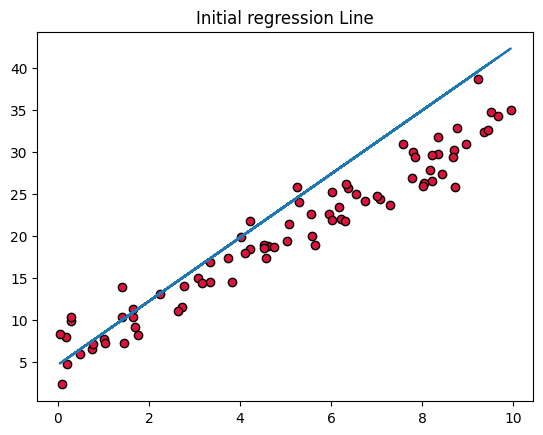

In [151]:
plt.plot(X_train,y_pred)
plt.scatter(X_train,Y_train, color = "crimson", edgecolors = "k")
plt.title ("Initial regression Line")

**Your interpretation / answer:**

The *initial regression line* may not fit the data well because we're gaving **random** coefficient $a,b$ .
The goal of linear regression is 
to find **new coefficients** that **fit** the line better. 

## C. Mean Squared Error (MSE)

The mean squared error is

$$\operatorname{MSE}=\frac1n\sum_{i=1}^n(y_i-\hat y_i)^2.$$

#### Question 10

Write a Python function named `mse()` that computes the MSE from the true and predicted values.

In [152]:
def mse(y,y_pred):
    return np.mean((y -y_pred) ** 2)

#### Question 11

Use the **initial** parameters `a` and `b` to generate training predictions and display their MSE.

In [153]:
train_mse = mse(Y_train,y_pred)
display(Math(fr"Training\_MSE: {train_mse:.4f}" ))

<IPython.core.display.Math object>

#### Question 12

Explain what a **large MSE** indicates about model predictions.

**Your interpretation / answer:**

* It means that the initial line is quite far from the set of data.

## D. Analytical Solution: Least Squares

Estimate $a$ and $b$ analytically from the **training data**:

$$a=\frac{\sum_i(X_i-\bar X)(y_i-\bar y)}{\sum_i(X_i-\bar X)^2},\qquad b=\bar y-a\bar X.$$

#### Question 13

Implement `least_squares(X, y)` from scratch, returning the estimated slope and intercept. **Do not use** `LinearRegression()`.

In [154]:
def least_squares(X,y):
    X_moy = np.sum(X)/len(X)
    y_moy = np.sum(y)/len(y)
    a = np.sum((X - X_moy)*(y - y_moy))
    a /= np.sum((X - X_moy)**2) 
    return a, (y_moy - a * X_moy)

#### Question 14

Calculate training predictions using the Least Squares parameters and display their MSE.

In [155]:
a_new , b_new = least_squares(X_train,Y_train)
display(Math(f"a = {a_new:.3f}"))
display(Math(f"b = {b_new:.3f}"))
new_mse = mse(Y_train,a_new * X_train + b_new)
display(Math(rf"New\_MSE = {new_mse:.3f}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Question 15

Compare the Least Squares training MSE with the initial training MSE. Explain why the analytical solution generally improves the fit.

In [156]:
display(Math(rf"Initial\_MSE = {train_mse:.3f}"))
display(Math(rf"New\_MSE = {new_mse:.3f}"))
display(Math(rf"Difference \simeq  {(train_mse - new_mse):.0f}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Your interpretation / answer:**

* It generally improves the fit because we use directly the coordinates of our data set to set our $a,b$ 

#### Question 16

Plot the training observations and the **Least Squares regression line**.

Text(0.5, 1.0, 'Less Squares Line')

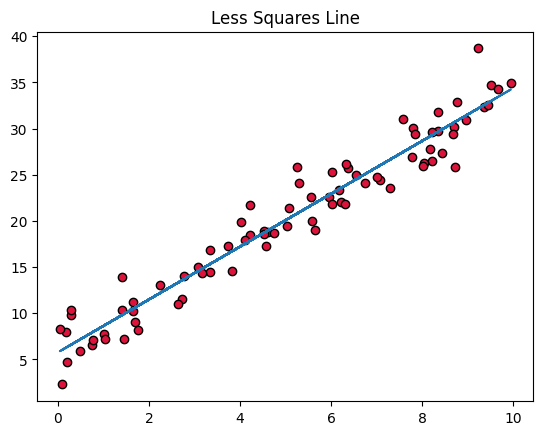

In [157]:
plt.plot(X_train,a_new * X_train + b_new)
plt.scatter(X_train,Y_train, color = "crimson", edgecolors = "k")
plt.title ("Less Squares Line")

## E. Optimization Using Gradient Descent

For $\hat y=aX+b$ and MSE loss, the gradients are

$$\frac{\partial L}{\partial a}=-\frac{2}{n}\sum_i X_i(y_i-\hat y_i), \qquad \frac{\partial L}{\partial b}=-\frac{2}{n}\sum_i(y_i-\hat y_i).$$

Update the parameters using

$$a\leftarrow a-\alpha\frac{\partial L}{\partial a},\qquad b\leftarrow b-\alpha\frac{\partial L}{\partial b}.$$

#### Question 17

Reinitialize the parameters `a` and `b` randomly; do **not** reuse Least Squares parameters.

In [158]:
a = rng.uniform(0,5)  
b = rng.uniform(0,5)

#### Question 18

Implement `gradient_descent()` to initialize the parameters; compute predictions and gradients at each iteration; update the parameters; calculate MSE after each update; store it in a list named `history`; and return `a`, `b`, and `history`.

In [159]:
def gradient_descent(x,y,a,b,alpha,iterations):
    m = len(x)
    history = []
    for _ in range(iterations):
        dy = a * x + b - y
        grad_a = np.sum(x * dy) / m
        grad_b = np.sum(dy) / m
        a = a - alpha * grad_a
        b = b - alpha * grad_b   
        history.append(mse(y,a * x +b))
    return a,b,history

#### Question 19

Train the model with **learning rate 0.01** for **1,000 iterations**.

In [160]:
N = 1000 
a,b,history = gradient_descent(X_train,Y_train,a,b,0.01,N)

#### Question 20

Display the final estimated `a` and `b`, and the final training MSE.

In [161]:
display(Math(f"a = {a:.3f}"))
display(Math(f"b = {b:.3f}"))
display(Math(rf"Final\_MSE = {history[-1]:.3f}"))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### Question 21

Plot the **loss curve**, with iteration number on the horizontal axis and MSE on the vertical axis.

Text(0.5, 1.0, 'Loss Curve')

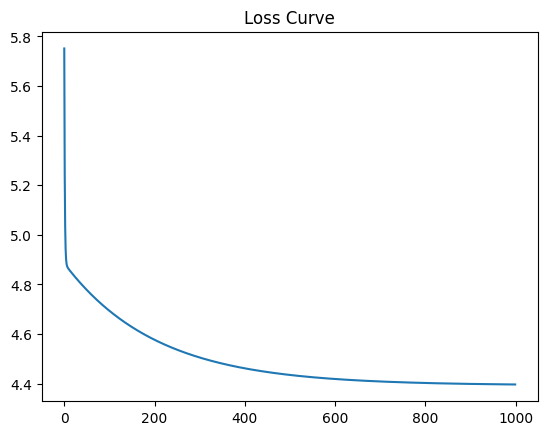

In [162]:
plt.plot(range(N),history)
plt.title ("Loss Curve")

#### Question 22

Interpret the loss curve. Does MSE decrease and stabilize? What happens when the learning rate is too small or too large?

**Your interpretation / answer:**

The MSE decrease and stabilize.

When $\alpha$ is too small the model takes too *long* to reach. 

If it's too large it will miss the value we want to reach , big steps make $a,b$ go far.

## F. Comparison of the Two Methods

#### Question 23

Plot the training observations and the regression line obtained with **Gradient Descent**.

Text(0.5, 1.0, 'Gradient Descent Line')

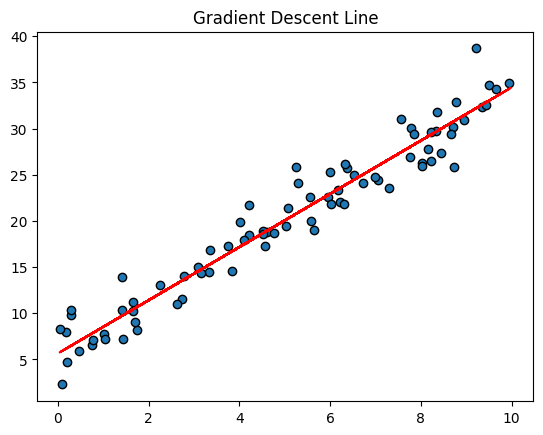

In [163]:
plt.plot(X,a*X+b, color ="r")
plt.scatter(X_train,Y_train, edgecolors = 'k')
plt.title ("Gradient Descent Line")

#### Question 24

Create a **single plot** showing training observations, the Least Squares line in **solid blue**, and the Gradient Descent line in **dashed blue**. Add a legend.

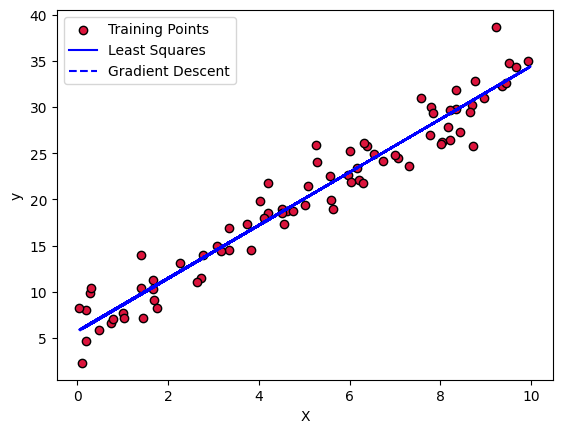

In [164]:
ax.plot(X,a_new * X + b_new, color = "blue" ,linestyle = "-",label = "Least Squares")
ax.plot(X,a * X + b, color = "blue" ,linestyle = "--",label = "Gradient Descent")
ax.legend()
fig

#### Question 25

Compare the estimated parameters and training MSE values of Least Squares and Gradient Descent. Are the methods expected to give similar results?

In [165]:
display(Math(r"Gradient Descent \quad Least Squares"))
display(Math(rf"a = {a:.3f} \qquad \quad \quad a = {a_new:.3f}"))
display(Math(rf"b = {b:.3f} \qquad \quad \quad b = {b_new:.3f}"))
display(Math(rf"MSE = {history[-1]:.3f} \qquad MSE = {new_mse:.3f}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Your interpretation / answer:**

* they are expected to produce very similar parameter estimates and training MSE values 

#### Question 26

Using the parameters learned by Gradient Descent, predict target values for the **test set**.

In [166]:
Y_pred_gd = a * X_test + b

#### Question 27

Calculate and display the **test MSE**. Explain why the test set must not be used to update model parameters.

In [167]:
test_mse = mse(Y_test,Y_pred_gd)
display(Math(rf"Test\_MSE = {test_mse:.3f} "))

<IPython.core.display.Math object>

**Your interpretation / answer:**

* Simply , if we used the test set in the learning process *(update the parameters)*, In the test phase, the model **saw** the values before.

#### Question 28

Compare **training MSE** and **test MSE**. What can you conclude about generalization to unseen data?

In [168]:
display(Math(rf"Train\_MSE = {history[-1]:.3f} \qquad Test\_MSE = {test_mse:.3f}"))

<IPython.core.display.Math object>

**Your interpretation / answer:**

* Since :$$\displaystyle Train\_MSE = 3.789 < Test\_MSE = 4.777$$

$\Rightarrow$ The test MSE is higher, so the model makes somewhat larger errors on unseen data. 

$\quad$ The gap is small, suggesting it generalizes reasonably well, with some loss on performance.


---
# Part II — Linear Regression on Nonlinear Data

**Objective:** Test the limits of a straight-line model on quadratic data, then use polynomial features to represent a curved relationship. Use separate variables so your Part I results remain available.

## A. Polynomial Data Generation

#### Question 1

Generate a **new dataset** containing 200 input values `X` uniformly distributed between **−3 and 3**.

In [169]:
X = np.random.uniform(-3, 3, 200)

#### Question 2

Generate the target values using

$$y=2X^2+3X+4+\varepsilon,\qquad\varepsilon\sim\mathcal{N}(0,2^2).$$

In [170]:
eps = np.random.normal(0, 2, size=len(X))
Y = 2 * X**2 + 3 * X + 4 + eps

#### Question 3

Split this dataset into **80% training** and **20% testing**, using the same shuffled-index method as Part I.

In [171]:
indices = np.random.permutation(len(X))
split = int(0.8 * len(X))

X_train, X_test = X[indices[:split]], X[indices[split:]]
Y_train, Y_test = Y[indices[:split]], Y[indices[split:]]

#### Question 4

Create a scatter plot of the generated data. Describe the relationship between `X` and `y`.

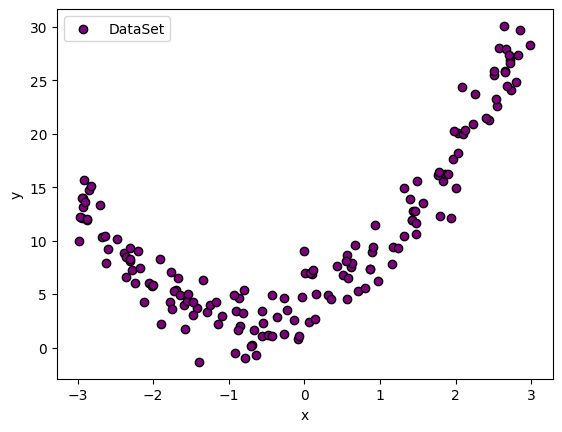

In [172]:
plt.scatter(X_train,Y_train,label = "DataSet", color = "purple", edgecolors = "k")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()

**Your interpretation / answer:**

* $X$ and $y$ have a nonlinear, approximately quadratic relationship: the data follows a curve rather than a straight line.

## B. Applying Simple Linear Regression

#### Question 5

Apply your **Part I Gradient Descent implementation** to the nonlinear data, keeping the simple linear model

$$\hat y=aX+b.$$

In [173]:
Y_pred = a * X_train + b

#### Question 6

Plot the observations together with the fitted **straight regression line**.

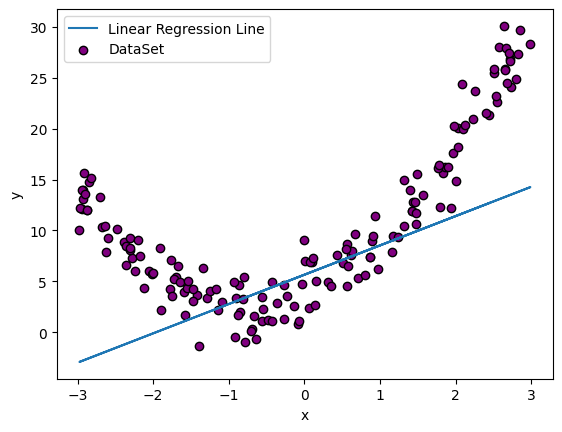

In [174]:
plt.plot(X_train,Y_pred, label = "Linear Regression Line")
plt.scatter(X_train,Y_train,label = "DataSet", color = "purple", edgecolors = "k")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()

#### Question 7

Calculate both **training MSE** and **test MSE** for the fitted straight-line model.

In [175]:
display(Math(rf"Train\_MSE = {mse(Y_train,Y_pred):.3f} \qquad Test\_MSE = {mse(Y_test,a * X_test + b):.3f}"))

<IPython.core.display.Math object>

#### Question 8

Compare these results with Part I. Explain why the straight-line model may fit the nonlinear data poorly even after Gradient Descent converges.

In [176]:
display(Math(r"\quad Linear Regression(Part\_I)"))
display(Math(rf"Train\_MSE = {history[-1]:.3f} \qquad Test\_MSE = {test_mse:.3f}"))
display(Math(r"\quad Linear Regression(Part\_II)"))
display(Math(rf"Train\_MSE = {mse(Y_train,Y_pred):.3f} \qquad Test\_MSE = {mse(Y_test,a * X_test + b):.3f}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Your interpretation / answer:**

* The straight-line model could represent the approximately linear relationship, so it achieved a lower MSE. The new data has a curved relationship, which a straight line cannot capture.

#### Question 9

What do you observe about the shape of the data, the fitted line, and the prediction errors? Does successful optimization guarantee that the model is appropriate? Justify your answer.

**Your interpretation / answer:**

* The data is curved, but the fitted line is straight, so its errors show a pattern. Gradient Descent can find the best line, but that doesn’t make a straight-line model suitable for nonlinear data.

## C. Extension: Polynomial Regression

#### Question 10

Extend the model by adding a quadratic feature:

$$\hat y=w_0+w_1X+w_2X^2.$$

In [177]:
w = rng.uniform(-3, 3)
Y_pred_qr = Y_pred +  w * X_train **2

#### Question 11

Explain how the additional feature `X²` allows the model to represent a nonlinear relationship.

**Your interpretation / answer:**

*The $X^2$ is the feature that make our model go from *linear* to *non-linear (curved function)*.

#### Question 12

Fit a degree-2 polynomial regression model using scikit-learn’s `PolynomialFeatures` and `LinearRegression`.

In [178]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

X_qr = X_train.reshape(-1, 1)

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X_qr)

model = LinearRegression()
model.fit(X_poly, Y_train)
Y_pred_qr = model.predict(X_poly) # Quadratic Regression

#### Question 13

Plot the observations, simple linear regression line, and quadratic regression curve **on the same figure**.

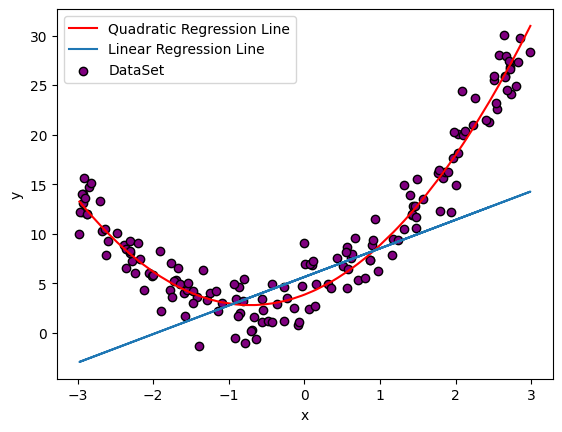

In [179]:
order = np.argsort(X_train)
plt.plot(X_train[order], Y_pred_qr[order], label="Quadratic Regression Line", color = "r")
plt.plot(X_train,a * X_train + b, label = "Linear Regression Line")
plt.scatter(X_train,Y_train,label = "DataSet", color = "purple", edgecolors = "k")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()

#### Question 14

Compare training and testing MSE of the linear and polynomial models. Which is more appropriate for this dataset, and why?

In [180]:
# Calculating the MSE for the polynomial model
X_test_poly = poly.transform(X_test.reshape(-1, 1))
Y_pred_qr_test = model.predict(X_test_poly)

display(Math(r"Linear Regression \qquad \quad Non-LinearRegression"))
display(Math(rf"Train\_MSE = {mse(Y_train,Y_pred):.3f} \qquad Train\_MSE = {mse(Y_train,Y_pred_qr):.3f}"))
display(Math(rf"Test\_MSE = {mse(Y_test,a * X_test + b):.3f} \qquad Test\_MSE = {mse(Y_test, Y_pred_qr_test):.3f}"))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Your interpretation / answer:**

* The more appropriate is the *Polyinomial* model , because it fits better our *dataset*.

---
# Part III — Overfitting and Regularization

**Objective:** Use the real Diabetes regression dataset to examine overfitting and compare unregularized polynomial regression with Ridge (L2) and Lasso (L1).

## A. Loading and Preparing a Real Dataset

#### Question 1

Import `load_diabetes` from `sklearn.datasets` and load the dataset.

In [181]:
from sklearn.datasets import load_diabetes
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
import pandas as pd

X_d, y_d = load_diabetes(return_X_y=True)


#### Question 2

Display the **number of observations**, **number of features**, and **target shape**.

In [182]:
display(Math(fr"Observations: {len(X_d)} \\ Features: {X_d.shape[1]} \\ Target shape: {y_d.shape}"))

<IPython.core.display.Math object>

#### Question 3

Split the dataset using `train_test_split()` with `test_size=0.2` and `random_state=42`.

In [183]:
X_d_train, X_d_test, y_d_train, y_d_test = train_test_split(X_d, y_d, test_size=.2, random_state=42)
display(Math(fr"Train\_Shape: {X_d_train.shape} \\ Test\_Shape: {X_d_test.shape}"))

<IPython.core.display.Math object>

#### Question 4

Explain why the **test set must remain separate** from model training.

**Your interpretation / answer:**

* So we can evaluate later our model to *unseen* data, so we can know if it generalize our dataset or no.

## B. Creating an Overfitting Scenario

#### Question 5

Create a pipeline containing `PolynomialFeatures` of high degree (e.g., **5**) followed by `LinearRegression`.

In [184]:
from sklearn.pipeline import make_pipeline
degree5_model = make_pipeline(
    PolynomialFeatures(degree=5, include_bias=False),
    LinearRegression()
)

#### Question 6

Fit the polynomial regression model using **only training data**.

In [185]:
degree5_model.fit(X_d_train, y_d_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('polynomialfeatures', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",5
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'
Name,Type,Value


#### Question 7

Calculate **training MSE** and **test MSE**.

In [186]:
train_mse_5 = mean_squared_error(y_d_train, degree5_model.predict(X_d_train))
test_mse_5 = mean_squared_error(y_d_test, degree5_model.predict(X_d_test))

display(Math(fr"Training\_MSE: {train_mse_5:.4f} \quad Testing\_MSE: {test_mse_5:.4f}"))

<IPython.core.display.Math object>

#### Question 8

Compare training and test errors. Is training error much lower than testing error?

**Your interpretation / answer:**

* If the training MSE is much lower than the testing MSE, the model is likely *overfitting*

#### Question 9

Explain **overfitting** and how model complexity can contribute to it.

**Your interpretation / answer:**

* Overfitting means the model fits the training data well but does not predict unseen data as well. A high polynomial degree makes the model more complex

#### Question 10

Repeat the experiment for polynomial degrees **1, 2, 3 and 5**. Record **training MSE and testing MSE** for each degree in a table.

In [187]:
degrees = [1, 2, 3, 5]
degree_models = {}
results = []

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )
    model.fit(X_d_train, y_d_train)
    degree_models[degree] = model

    results.append({
        "Degree": degree,
        "Training MSE": mean_squared_error(y_d_train, model.predict(X_d_train)),
        "Testing MSE": mean_squared_error(y_d_test, model.predict(X_d_test))
    })

results_df = pd.DataFrame(results)
display(results_df.round(2))

,Degree,Training MSE,Testing MSE
0,1,2868.55,2900.19
1,2,2393.14,3096.03
2,3,871.20,32911.96
3,5,0.00,143012.59


#### Question 11

Plot training and testing MSE **against polynomial degree**. Report which degree has the lowest observed test MSE among those tested.

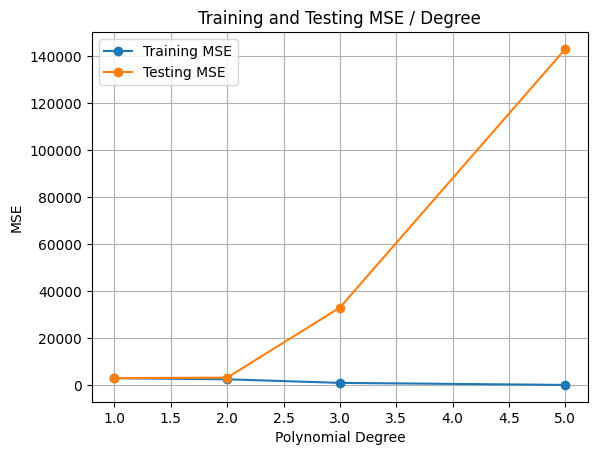

<IPython.core.display.Math object>

In [188]:
import matplotlib.pyplot as plt

plt.plot(results_df["Degree"], results_df["Training MSE"], marker="o", label="Training MSE")
plt.plot(results_df["Degree"], results_df["Testing MSE"], marker="o", label="Testing MSE")

plt.xlabel("Polynomial Degree")
plt.ylabel("MSE")
plt.title("Training and Testing MSE / Degree")
plt.legend()
plt.grid(True)
plt.show()

best_degree = results_df.loc[results_df["Testing MSE"].idxmin(), "Degree"]
display(Math(fr"Lowest Observed Test MSE: \qquad Degree: {best_degree}"))

**Your interpretation / answer:**

*...*

## C. Ridge Regression

Ridge adds an L2 penalty:

$$J(\mathbf w)=\frac1n\sum_i(y_i-\hat y_i)^2+\lambda\sum_{j=1}^{p}w_j^2.$$

**Implementation note:** Scikit-learn names the penalty parameter `alpha` and uses a different normalization convention. In this practical, you may use the listed values as scikit-learn `alpha` settings, but make that convention explicit in your interpretations.

#### Question 12

Import `Ridge` from `sklearn.linear_model`.

In [189]:
from sklearn.linear_model import Ridge

#### Question 13

Create a pipeline with **polynomial feature expansion**, `StandardScaler`, and **Ridge Regression**.

In [190]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline

def create_ridge_model(alpha):
    return make_pipeline(
        PolynomialFeatures(degree=5, include_bias=False),
        StandardScaler(),
        Ridge(alpha=alpha)
    )

#### Question 14

Using polynomial degree **5**, train separate Ridge models for regularization values

$$\lambda\in\{0.01,0.1,1,10,100\}.$$

In [191]:
alphas = [0.01, 0.1, 1, 10, 100]
ridge_results = []
ridge_models = {}

#### Question 15

For each value of regularization strength, calculate the **training and testing MSE**.

In [192]:
for alpha in alphas:
    model = create_ridge_model(alpha)
    model.fit(X_d_train, y_d_train)
    ridge_models[alpha] = model

    ridge_results.append({
        "Alpha": alpha,
        "Training MSE": mean_squared_error(y_d_train, model.predict(X_d_train)),
        "Testing MSE": mean_squared_error(y_d_test, model.predict(X_d_test))
    })

#### Question 16

Store the results in a table and report the value giving the **lowest observed test MSE**.

In [193]:
ridge_table = pd.DataFrame(ridge_results)
display(ridge_table.round(2))

best_alpha = ridge_table.loc[ridge_table["Testing MSE"].idxmin(), "Alpha"]

,Alpha,Training MSE,Testing MSE
0,0.01,0.03,67050.57
1,0.10,2.04,59329.81
2,1.00,50.88,38924.92
3,10.00,354.47,18284.59
4,100.00,1097.49,5317.92


**Your interpretation / answer:**

Lowest observed test MSE is with $\alpha : 100.0$

#### Question 17

Explain how increasing regularization strength affects model complexity and prediction errors.

**Your interpretation / answer:**

*...*

## D. Lasso Regression

Lasso adds an L1 penalty:

$$J(\mathbf w)=\frac1n\sum_i(y_i-\hat y_i)^2+\lambda\sum_{j=1}^{p}|w_j|.$$

Unlike Ridge, Lasso can set some coefficients exactly to zero.

#### Question 18

Import `Lasso` from `sklearn.linear_model`.

In [194]:
from sklearn.linear_model import Lasso

#### Question 19

Create a pipeline with **polynomial feature expansion**, feature standardization, and **Lasso Regression**.

In [195]:
def create_lasso_model(alpha):
    return make_pipeline(
        PolynomialFeatures(degree=5, include_bias=False),
        StandardScaler(),
        Lasso(alpha=alpha, max_iter=20000)
    )

#### Question 20

Train Lasso using the **same degree 5** and **same five regularization strengths** as Ridge.

In [196]:
lasso_results = []
lasso_models = {}

for alpha in alphas:
    model = create_lasso_model(alpha)
    model.fit(X_d_train, y_d_train)
    lasso_models[alpha] = model

    predictions = model.predict(X_d_test)
    zero_count = np.sum(model.named_steps["lasso"].coef_ == 0)

    lasso_results.append({
        "Alpha": alpha,
        "Training MSE": mean_squared_error(
            y_d_train, model.predict(X_d_train)
        ),
        "Testing MSE": mean_squared_error(y_d_test, predictions),
        "Zero Coefficients": zero_count
    })

lasso_table = pd.DataFrame(lasso_results)
display(lasso_table.round(2))

c:\Users\Djalil\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.734484e+03, tolerance: 2.145e+02
  model = cd_fast.enet_coordinate_descent(
c:\Users\Djalil\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.704615e+02, tolerance: 2.145e+02
  model = cd_fast.enet_coordinate_descent(


,Alpha,Training MSE,Testing MSE,Zero Coefficients
0,0.01,19.43,40254.26,2505
1,0.10,297.98,16803.24,2718
2,1.00,1694.23,3291.83,2876
3,10.00,3222.65,2853.88,2996
4,100.00,6076.40,5361.53,3002


#### Question 21

Calculate and compare the **training and testing MSE** for all Lasso regularization strengths.

#### Question 22

Count the fitted Lasso coefficients that are **exactly zero**. Explain what this says about feature selection.

**Your interpretation / answer:**

*...*

#### Question 23

Compare Lasso with Ridge. Which gives better test performance **under the chosen experimental settings**?

**Your interpretation / answer:**

*...*

## E. Final Comparison and Interpretation

#### Question 24

Build a summary table of **unregularized polynomial regression**, **Ridge**, and **Lasso**. Include polynomial degree, regularization parameter, training MSE, and testing MSE.

**Your interpretation / answer:**

*...*

#### Question 25

Discuss the effect of regularization on overfitting and generalization.

**Your interpretation / answer:**

*...*

#### Question 26

Explain why regularization hyperparameters should be selected using **validation data or cross-validation**, rather than repeatedly optimizing choices using the test set.

**Your interpretation / answer:**

*...*